# 02 — Linear Classifiers: SVM and Softmax

**CS231n Lecture 3.** kNN carried the whole training set around. A *parametric*
model throws it away and keeps only `W`:

$$ f(x_i; W, b) = W x_i + b $$

Training is now expensive and prediction is one matrix multiply — the cost
profile finally points the right way.

This notebook is where the course gets real, because you derive and implement
**four gradients by hand** and check every one numerically:

| You write | Shape of the idea |
|---|---|
| `svm_loss_naive` | hinge loss + gradient, explicit loops |
| `svm_loss_vectorized` | same thing as matrix algebra |
| `softmax_loss_naive` | cross-entropy + gradient, explicit loops |
| `softmax_loss_vectorized` | the famous `p - y_onehot` |

Shape convention, fixed for the whole series:

```
X : (N, D)    rows are examples
W : (D, C)    columns are class weight vectors
scores = X.dot(W)   ->  (N, C)
```

In [35]:
import sys, os, time
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from cs231n_utils import (get_cifar10, CLASSES, rel_error, grade, show_solution,
                          use, show_images, plot_weight_templates, plot_series,
                          eval_numerical_gradient, grad_check_sparse, setup_plots,
                          plot_score_geometry, plot_hyperplane_regions)

setup_plots()
np.random.seed(0)

## 1. The parametric approach and the bias trick

$Wx + b$ has two parameter blocks to carry around, and writing `+ b` in every
gradient is a nuisance. The **bias trick** folds it away: append a constant `1`
to every feature vector and an extra row to `W`.

$$ W x + b \;=\; [W \;|\; b] \begin{bmatrix} x \\ 1 \end{bmatrix} $$

CIFAR images become 3073-dimensional, `W` becomes `(3073, 10)`, and from here on
there is only one parameter array.

**Preprocessing matters here in a way it didn't for kNN.** Subtract the mean
image. If every feature is in `[0, 255]` and strictly positive, every gradient
`dW[:, j] += X[i]` has the same sign pattern across the whole row, so all weights
for a class move together — the zig-zag problem you'll see again in notebook 08.

In [36]:
data = get_cifar10(num_train=5000, num_val=500, num_test=500,
                   flatten=True, subtract_mean=True)
X_train, y_train = data['X_train'], data['y_train']
X_val,   y_val   = data['X_val'],   data['y_val']
X_test,  y_test  = data['X_test'],  data['y_test']

# bias trick: append a column of ones
def add_bias(X):
    return np.hstack([X, np.ones((X.shape[0], 1))])

X_train_b, X_val_b, X_test_b = map(add_bias, (X_train, X_val, X_test))
print("after bias trick:", X_train_b.shape, "-> W will be (%d, 10)" % X_train_b.shape[1])
print("last column is all ones:", (X_train_b[:, -1] == 1))

train (5000, 3072)  val (500, 3072)  test (500, 3072)
after bias trick: (5000, 3073) -> W will be (3073, 10)
last column is all ones: [ True  True  True ...  True  True  True]


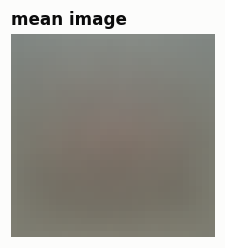

In [37]:
# What the mean image looks like -- this is what got subtracted.
fig, ax = plt.subplots(figsize=(2.4, 2.4))
ax.imshow(data['mean_image'].reshape(32, 32, 3).astype('uint8'))
ax.set_title("mean image"); ax.axis('off')
plt.show()

## 1b. What `w·x + b` means, geometrically

Before the loss functions, look at what a single score function does to space.
`f(x) = w·x + b` is a **hyperplane**: the set `{x : w·x + b = 0}` is the
decision boundary, and `w` is its **normal vector** — it points in the
direction the score increases fastest. Everything on one side scores positive,
everything on the other scores negative, and how far a point sits from the
line (in the direction of `w`) *is* the score, up to the scale `|w|`.

This is the 2D stand-in for the same computation `scores = X.dot(W)` runs 3073
dimensions at a time.

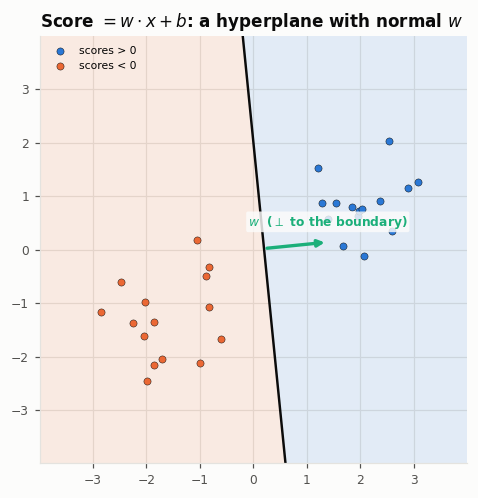

In [38]:
geo_rng = np.random.RandomState(3)
w_demo2d = np.array([5.0, 0.5])
b_demo2d = -1.0

Xg = np.concatenate([geo_rng.randn(15, 2) * 0.6 + [2.0, 1.0],
                     geo_rng.randn(15, 2) * 0.6 + [-1.5, -1.0]])
yg = np.concatenate([np.zeros(15, dtype=int), np.ones(15, dtype=int)])

plot_score_geometry(w_demo2d, b_demo2d, X=Xg, y=yg, class_names=['scores > 0', 'scores < 0'])
plt.show()

Notice `w` points from the negative side toward the positive side, at a right
angle to the boundary — not toward either cluster of points. Rotating `w`
rotates the boundary; scaling `w` (without changing `b`'s relative pull)
leaves the boundary exactly where it is and only changes how fast the score
grows away from it. That second fact is the whole reason $\Delta$ and
$\lambda$ trade off against each other below.

## 2. Multiclass SVM (hinge) loss

For example $i$ with correct label $y_i$, let $s = f(x_i; W)$. The loss is

$$ L_i = \sum_{j \neq y_i} \max\left(0,\; s_j - s_{y_i} + \Delta\right) $$

Read it as a demand: **the correct class score must beat every other class score
by at least $\Delta$.** If it does, that term contributes zero and the SVM stops
caring. That last part is the defining property — hinge loss is satisfiable.

### Why $\Delta = 1$ and nobody tunes it

$\Delta$ and the regularisation strength $\lambda$ control the same thing from
opposite ends. Scaling `W` by a constant scales all score *differences* by that
constant, so any $\Delta$ can be absorbed by rescaling `W` — and what limits how
large `W` can get is $\lambda$. Two knobs, one degree of freedom. Fix
$\Delta = 1$, tune $\lambda$.

### Regularisation

$$ L = \underbrace{\frac{1}{N}\sum_i L_i}_{\text{data loss}} \;+\; \underbrace{\lambda \sum_k\sum_l W_{k,l}^2}_{\text{regularisation}} $$

Without it, the `W` that separates the data is not unique — `2W` also has zero
data loss and any multiple of it does too. L2 regularisation breaks the tie by
preferring **diffuse** weights: given `x = [1,1,1,1]`, the weight vectors
`[1,0,0,0]` and `[0.25]*4` produce the same score, but the second has a quarter
of the L2 penalty. Spreading attention across many pixels instead of betting on
one generalises better.

> Note the convention used throughout this series: the penalty is
> $\lambda \sum W^2$, so its gradient is $2\lambda W$. CS231n sometimes writes
> $\tfrac12 \lambda \sum W^2$ to make the 2 cancel. Pick one and be consistent —
> a missing factor of 2 is a classic gradient-check failure.

### Deriving the gradient

Differentiate one term of $L_i$ with respect to the weight vectors. For a wrong
class $j \neq y_i$ whose margin is violated ($s_j - s_{y_i} + \Delta > 0$):

$$ \nabla_{w_j} L_i = x_i \qquad\qquad \nabla_{w_{y_i}} L_i = -x_i $$

and when the margin is satisfied, both are zero. The correct class accumulates
$-x_i$ **once for every violated margin in that row** — that count is the thing
people forget, and it is what makes the vectorised version non-obvious.

In words: *push the offending class's template away from this image, and pull
the correct class's template toward it.*

### TODO 1 — `svm_loss_naive`

Loops are fine. Return `(loss, dW)`, both averaged over the batch and with
regularisation added.

In [39]:
def svm_loss_naive(W, X, y, reg):
    """W (D, C), X (N, D), y (N,) ints, reg float. Returns (loss, dW)."""
    dW = np.zeros_like(W)
    num_train, num_classes = X.shape[0], W.shape[1]
    loss = 0.0

    for i in range(num_train):
        # TODO
        #   scores = X[i].dot(W)
        #   for each j != y[i]: margin = scores[j] - scores[y[i]] + 1
        #   if margin > 0: accumulate into loss, dW[:, j] and dW[:, y[i]]
        scores = X[i].dot(W)
        for j in range(num_classes) :
            if j == y[i]:
                continue
            margin = scores[j] - scores[y[i]] + 1
            if margin < 0:
                continue
            elif margin >= 0:
                loss += margin
                dW[:,j] += X[i]
                dW[:,y[i]] -= X[i]
        pass

    # TODO: average over num_train, then add reg * sum(W*W) and its gradient
        
    loss /= num_train
    loss += reg*np.sum(W*W)
    dW /= num_train
    dW += reg*2*(W)
    return loss, dW

In [40]:
grade('nb02', 'svm_loss_naive', svm_loss_naive)

[PASS] svm_loss_naive  case 1/2  out[0]  rel error 0.000e+00
[PASS] svm_loss_naive  case 1/2  out[1]  rel error 0.000e+00
[PASS] svm_loss_naive  case 2/2  out[0]  rel error 0.000e+00
[PASS] svm_loss_naive  case 2/2  out[1]  rel error 0.000e+00
--> svm_loss_naive looks correct.


True

### \Check it numerically — the habit that saves you hours

`grade` compares you to a reference, but in real work there is no reference.
There is only this: perturb a weight, see how the loss moves, compare to what
your analytic gradient claimed.

In [41]:
svm_naive = use('nb02', 'svm_loss_naive', svm_loss_naive)

W_dev = np.random.randn(X_train_b.shape[1], 10) * 0.0001
Xb, yb = X_train_b[:200], y_train[:200]

loss, grad = svm_naive(W_dev, Xb, yb, 0.0)
print("loss with tiny random W: %.4f   (sanity: should be near %d)" % (loss, 10 - 1))
print("\nspot-checking 8 random coordinates, reg = 0:")
f = lambda w: svm_naive(w, Xb, yb, 0.0)[0]
grad_check_sparse(f, W_dev.copy(), grad, num_checks=10)

loss with tiny random W: 8.7801   (sanity: should be near 9)

spot-checking 8 random coordinates, reg = 0:
  numeric +8.456624   analytic +8.456624   rel error 1.07e-11
  numeric +7.887304   analytic +8.019792   rel error 8.33e-03
  numeric +0.829426   analytic +1.024408   rel error 1.05e-01
  numeric -20.621495   analytic -20.621495   rel error 1.84e-11
  numeric +10.553910   analytic +10.553910   rel error 7.34e-12
  numeric +35.655795   analytic +35.655795   rel error 1.24e-12
  numeric +14.506675   analytic +14.506675   rel error 1.52e-11
  numeric -17.217565   analytic -17.217565   rel error 4.04e-12
  numeric +9.182580   analytic +9.182580   rel error 6.05e-12
  numeric -10.841370   analytic -10.841370   rel error 6.00e-12


np.float64(0.10517769804107917)

**Sanity check on that first number.** With `W` near zero, all scores are near
zero, so every margin is $0 - 0 + 1 = 1$ and there are `C - 1 = 9` of them. If
your loss is not close to 9, you have a bug before you even look at the
gradient. Every loss function in this course has a cheap "what should it be at
initialisation" check — always do it.

In [42]:
# Now with regularisation on -- this catches a missing factor of 2 in d(reg)/dW.
loss, grad = svm_naive(W_dev, Xb, yb, 5e1)
print("spot-check with reg = 5e1:")
f = lambda w: svm_naive(w, Xb, yb, 5e1)[0]
worst = grad_check_sparse(f, W_dev.copy(), grad, num_checks=8)
print("\nworst relative error: %.2e" % worst)

spot-check with reg = 5e1:
  numeric +8.463637   analytic +8.463637   rel error 1.16e-11
  numeric +7.877978   analytic +8.010466   rel error 8.34e-03
  numeric +0.826641   analytic +1.021623   rel error 1.05e-01
  numeric -20.619422   analytic -20.619422   rel error 1.78e-11
  numeric +10.549964   analytic +10.549964   rel error 8.22e-12
  numeric +35.667208   analytic +35.667208   rel error 1.78e-12
  numeric +14.520888   analytic +14.520888   rel error 1.48e-11
  numeric -17.219365   analytic -17.219365   rel error 2.85e-12

worst relative error: 1.05e-01



\
\> **Expect some imprecision here, and know why.** The hinge has a *kink* at
> `margin = 0`. If a margin sits very near zero, the numeric gradient steps
> across the kink and the two sides genuinely disagree — the numeric gradient is
> the wrong answer, not yours. A handful of coordinates at `1e-3` amid many at
> `1e-9` is the signature of kinks, not bugs. Smooth losses like softmax should
> not show this.

### TODO 2 — `svm_loss_vectorized`

Now remove both loops. The pieces:

1. `scores = X.dot(W)` — `(N, C)`
2. pull out the correct-class score per row with
   `scores[np.arange(N), y]`, and keep it as a `(N, 1)` column so it broadcasts
3. `margins = np.maximum(0, scores - correct + 1)`, then zero the `y[i]` column
   of each row (otherwise every row contributes a spurious `+1`)
4. for the gradient, build a `(N, C)` **mask**: `1` where the margin was
   violated, and in the correct-class slot, *minus the number of violations in
   that row*
5. `dW = X.T.dot(mask) / N`

Step 4 is the whole exercise. Convince yourself `X.T.dot(mask)` is exactly the
`dW[:, j] += X[i]` accumulation, done by BLAS.

In [46]:
def svm_loss_vectorized(W, X, y, reg):
    # TODO: no python loops over examples or classes
    loss = 0.0
    dW = np.zeros_like(W)
    scores = X.dot(W)
    num_train = np.shape(X)[0]
    # correct_scores = scores[ np.arange(num_train) , y ][:, np.newaxis]
    # margins = np.maximum(0, scores - correct_scores + 1)
    # margins[np.arange(num_train), y] = 0
    # loss += np.sum(margins) 
    # loss /= num_train
    # loss += reg*np.sum(W*W)
    # mask = (margins > 0).astype(W.dtype)                # 1 where margin violated
    # mask[np.arange(num_train), y] = -np.sum(mask, axis=1)       # correct class: -(violation count)
    # dW = X.T.dot(mask) / num_train + 2 * reg * W

    correct_scores = scores[np.arange(num_train) , y][:,np.newaxis]
    scores = np.maximum(0,scores - correct_scores + 1)
    scores[np.arange(num_train),y] = 0
    loss += np.sum(scores)
    loss /= num_train
    loss += reg*np.sum(W*W)
    mask = (scores > 0).astype(W.dtype)
    mask[np.arange(num_train), y] = -np.sum(mask, axis=1)       # correct class: -(violation count)
    dW = X.T.dot(mask) / num_train + 2 * reg * W
    
    return loss, dW

In [47]:
grade('nb02', 'svm_loss_vectorized', svm_loss_vectorized)

[PASS] svm_loss_vectorized  case 1/2  out[0]  rel error 0.000e+00
[PASS] svm_loss_vectorized  case 1/2  out[1]  rel error 0.000e+00
[PASS] svm_loss_vectorized  case 2/2  out[0]  rel error 0.000e+00
[PASS] svm_loss_vectorized  case 2/2  out[1]  rel error 0.000e+00
--> svm_loss_vectorized looks correct.


True

In [45]:
svm_vec = use('nb02', 'svm_loss_vectorized', svm_loss_vectorized)

t0 = time.time(); ln, gn = svm_naive(W_dev, X_train_b, y_train, 5e1); tn = time.time() - t0
t0 = time.time(); lv, gv = svm_vec(W_dev, X_train_b, y_train, 5e1);  tv = time.time() - t0
print("naive      %.3f s   loss %.6f" % (tn, ln))
print("vectorized %.3f s   loss %.6f" % (tv, lv))
print("speedup %.0fx,  gradient rel error %.2e" % (tn / max(tv, 1e-9), rel_error(gn, gv)))

(falling back to the reference svm_loss_vectorized -- yours not filled in)
naive      0.363 s   loss 8.953233
vectorized 0.011 s   loss 8.953233
speedup 33x,  gradient rel error 1.10e-11


## 3. Softmax / cross-entropy

Same scores, different interpretation. The SVM treats scores as opaque numbers
that need to be ordered correctly. Softmax treats them as **unnormalised log
probabilities**:

$$ P(Y = k \mid X = x_i) = \frac{e^{s_k}}{\sum_j e^{s_j}} \qquad
   L_i = -\log P(Y = y_i \mid X = x_i) $$

### The numeric stability shift

$e^{s}$ overflows fast — scores of a few hundred are routine once training gets
going, and `np.exp(800)` is `inf`. `inf/inf` is `nan` and your run is dead.

The fix uses the fact that the softmax is invariant to a constant shift:

$$ \frac{e^{s_k}}{\sum_j e^{s_j}}
 = \frac{C e^{s_k}}{C \sum_j e^{s_j}}
 = \frac{e^{s_k + \log C}}{\sum_j e^{s_j + \log C}} $$

Choose $\log C = -\max_j s_j$, so the largest exponent becomes exactly 0. Now
`exp` is at most 1, never overflows, and the answer is unchanged.

**Do this every single time.** It costs one line and there is no downside.

### Deriving the gradient — the cleanest result in the course

With $p_k$ the softmax probability of class $k$:

$$ \frac{\partial L_i}{\partial s_k} = p_k - \mathbb{1}[k = y_i] $$

That's it. *Predicted probability minus the one-hot truth.* Then chain through
$s = xW$ to get $\nabla_W$.

Read it as an error signal: if the model said 0.7 for a class that wasn't the
answer, that class's score gets pushed down by 0.7. If it said 0.2 for the class
that *was* the answer, that score gets pushed up by 0.8. The size of the nudge is
exactly how wrong the model was.

### TODO 3 — `softmax_loss_naive`

In [50]:
def softmax_loss_naive(W, X, y, reg):
    dW = np.zeros_like(W)
    num_train, num_classes = X.shape[0], W.shape[1]
    loss = 0.0

    for i in range(num_train):
        # TODO
          # scores = X[i].dot(W);  SHIFT by -max before exp
          # probs  = exp(scores) / sum(exp(scores))
          # loss  += -log(probs[y[i]])
          # dW[:, j] += (probs[j] - (j == y[i])) * X[i]

        # scores = X[i].dot(W)
        # scores -= np.max(scores)
        # probs = np.exp(scores) / np.sum(np.exp(scores))
        # loss += -np.log(probs[y[i]])

        scores = X[i].dot(W)
        scores -= np.max(scores)
        probs = np.exp(scores)/np.sum(np.exp(scores))
        loss += -np.log(probs[y[i]])

        pass





    loss /= num_train
    # dW /= num_train
    loss += reg * np.sum(W * W)
    # dW += 2 * reg * W
    return loss, dW

In [51]:
grade('nb02', 'softmax_loss_naive', softmax_loss_naive)

[PASS] softmax_loss_naive  case 1/2  out[0]  rel error 0.000e+00
[FAIL] softmax_loss_naive  case 1/2  out[1]  rel error 1.000e+00
[PASS] softmax_loss_naive  case 2/2  out[0]  rel error 0.000e+00
[FAIL] softmax_loss_naive  case 2/2  out[1]  rel error 1.000e+00
--> softmax_loss_naive does not match the reference. Run show_solution('nb02', 'softmax_loss_naive') when you want to compare.


False

In [55]:
softmax_naive = use('nb02', 'softmax_loss_naive', softmax_loss_naive)

loss, grad = softmax_naive(W_dev, Xb, yb, 0.0)
print("loss with tiny random W: %.4f" % loss)
print("expected at init: -log(1/10) = %.4f" % (-np.log(0.1)))

print("\nspot-check (softmax is smooth, so expect uniformly small errors):")
f = lambda w: softmax_naive(w, Xb, yb, 0.0)[0]
grad_check_sparse(f, W_dev.copy(), grad, num_checks=8)

(falling back to the reference softmax_loss_naive -- yours does not match)
loss with tiny random W: 2.3284
expected at init: -log(1/10) = 2.3026

spot-check (softmax is smooth, so expect uniformly small errors):
  numeric +0.671071   analytic +0.671070   rel error 7.73e-08
  numeric +0.484208   analytic +0.484208   rel error 3.32e-08
  numeric -0.335387   analytic -0.335387   rel error 3.67e-08
  numeric -2.592156   analytic -2.592156   rel error 2.01e-08
  numeric +1.173459   analytic +1.173459   rel error 4.20e-08
  numeric +3.942844   analytic +3.942843   rel error 2.23e-08
  numeric +1.483191   analytic +1.483191   rel error 3.02e-08
  numeric -2.795515   analytic -2.795515   rel error 1.79e-08


np.float64(7.727475713141593e-08)

**The $-\log(1/C)$ check is the most useful sanity check in deep learning.** At
initialisation the model knows nothing, so it should assign $1/C$ to every class
and the loss should be $\log C$ — about `2.303` for 10 classes, `6.91` for 1000.
If your fresh model's loss is far from that, something is broken: wrong
initialisation scale, a missing softmax, labels off by one.

### TODO 4 — `softmax_loss_vectorized`

The `p - y_onehot` form makes this short. Build `probs` as `(N, C)`, copy it,
subtract 1 at the correct-class positions, divide by `N`, and one `X.T.dot(...)`
finishes it.

Watch `keepdims=True` on both the max and the sum — without it the `(N,)` result
broadcasts along the wrong axis and you get a silently wrong answer rather than
an error.

In [ ]:
def softmax_loss_vectorized(W, X, y, reg):
    # TODO: no python loops
    loss = 0.0
    dW = np.zeros_like(W)
    return loss, dW

In [ ]:
grade('nb02', 'softmax_loss_vectorized', softmax_loss_vectorized)

In [ ]:
softmax_vec = use('nb02', 'softmax_loss_vectorized', softmax_loss_vectorized)

t0 = time.time(); ln, gn = softmax_naive(W_dev, X_train_b, y_train, 5e1); tn = time.time() - t0
t0 = time.time(); lv, gv = softmax_vec(W_dev, X_train_b, y_train, 5e1);  tv = time.time() - t0
print("naive      %.3f s   loss %.6f" % (tn, ln))
print("vectorized %.3f s   loss %.6f" % (tv, lv))
print("speedup %.0fx,  gradient rel error %.2e" % (tn / max(tv, 1e-9), rel_error(gn, gv)))

## 4. SVM vs Softmax — the difference that actually matters

Same `f(x; W) = Wx`, same gradient plumbing, different demand on the scores.

Scores `[10, -2, 3]` with correct class 0:

- **SVM** ($\Delta = 1$): margins are already enormous. Loss **0**. Gradient
  **0**. The example is done; the SVM will never look at it again.
- **Softmax**: probability of class 0 is about 0.999, loss about 0.0009 — small,
  but **not zero**, and the gradient is not zero either. Softmax will keep
  pushing that 0.999 toward 1.0 forever.

> **SVM is satisfiable; softmax is never satisfied.** An SVM that has cleared
> every margin puts its remaining effort into the examples that are still wrong.
> Softmax always spends some gradient on examples it has already nailed.

In practice the difference in final accuracy is small. The difference in what
the loss *number* tells you is not: an SVM loss of 0 means "all margins clear",
while a softmax loss of 0 is unreachable, so softmax losses are only meaningful
compared to other softmax losses.

> **One caveat you'll see in the output below.** Push the correct score far
> enough and softmax's loss prints as exactly `0.000e+00`. That is float64
> underflow, not mathematics — the true value is around $e^{-97}$, which is
> smaller than the smallest representable double. The *claim* "softmax is never
> satisfied" is about the maths; the *arithmetic* gives up long before the maths
> does. Worth knowing which one you are looking at.

In [ ]:
# See it rather than take my word for it.
W_demo = np.eye(3)
x_demo = np.array([[10.0, -2.0, 3.0]])
y_demo = np.array([0])

svm_l, svm_g = svm_naive(W_demo, x_demo, y_demo, 0.0)
sm_l,  sm_g  = softmax_naive(W_demo, x_demo, y_demo, 0.0)
print("scores [10, -2, 3], correct class 0")
print("  SVM     loss %.6f   |grad| %.6f" % (svm_l, np.abs(svm_g).sum()))
print("  Softmax loss %.6f   |grad| %.6f" % (sm_l,  np.abs(sm_g).sum()))

# Crank the correct class up. SVM is pinned at 0; softmax keeps shrinking but
# never reaches it.
for top in [10.0, 20.0, 40.0, 100.0]:
    xd = np.array([[top, -2.0, 3.0]])
    sl, sg = svm_naive(W_demo, xd, y_demo, 0.0)
    ml, mg = softmax_naive(W_demo, xd, y_demo, 0.0)
    print("  top score %6.1f | SVM loss %.1f  grad %.1f "
          "| softmax loss %9.3e  grad %9.3e"
          % (top, sl, np.abs(sg).sum(), ml, np.abs(mg).sum()))

## 5. Train one, and look at what it learned

The training loop below is given to you — you write it properly in notebook 03.
The point here is the picture at the end.

In [ ]:
from solutions.nb02 import train_linear

W_svm, hist_svm = train_linear(svm_vec, X_train_b, y_train, 10,
                               learning_rate=1e-7, reg=2.5e4, num_iters=1500,
                               batch_size=200, verbose=True)

def accuracy(W, X, y):
    return float(np.mean(np.argmax(X.dot(W), axis=1) == y))

print("\nSVM     train %.3f   val %.3f" % (accuracy(W_svm, X_train_b, y_train),
                                           accuracy(W_svm, X_val_b, y_val)))

W_sm, hist_sm = train_linear(softmax_vec, X_train_b, y_train, 10,
                             learning_rate=1e-7, reg=2.5e4, num_iters=1500,
                             batch_size=200)
print("Softmax train %.3f   val %.3f" % (accuracy(W_sm, X_train_b, y_train),
                                         accuracy(W_sm, X_val_b, y_val)))

In [ ]:
def smooth(v, k=25):
    return np.convolve(np.asarray(v, float), np.ones(k) / k, mode='valid')

fig, ax = plt.subplots(figsize=(6.4, 3.6))
plot_series(ax, np.arange(len(smooth(hist_svm))),
            [('SVM', smooth(hist_svm)), ('Softmax', smooth(hist_sm))],
            "Training loss (25-iteration moving average)", "iteration", "loss")
plt.show()

The two curves are not on a comparable scale — hinge loss and cross-entropy
measure different things. Compare each curve to *itself* over time, never SVM's
number to softmax's.

In [ ]:
plot_weight_templates(W_svm, CLASSES, title="SVM — learned weight templates")
plt.show()

### Read these templates

This is the most informative picture in the first half of CS231n. Each panel is
literally the weight vector for one class, reshaped back into an image — so it
is a picture of *what that class's score detector is looking for*.

What is unmistakable at this training budget:

- **plane** and **ship** are blue-dominated. The classifier has learned "blue
  surroundings" at least as much as it has learned the object.
- **frog**, **deer** and **bird** are green-dominated, for the same reason.
- **horse** sits on a gold/tan field with a dark mass in the middle.

In other words the templates are driven substantially by **background colour
statistics**, not object shape — which is the same complaint as the nearest-
neighbour result in notebook 01, arrived at from a different direction.

Now the structural limitation. A linear classifier scores each class with a
single inner product, so it can express exactly **one prototype per class**.
Any class whose appearance is genuinely multi-modal — horses facing left and
horses facing right, cars of every colour — gets averaged into one blurry
compromise rather than represented as alternatives.

> The canonical illustration of this is the CS231n horse template, which
> trained on the full 50,000 images resolves into a horse with a head at
> *both* ends: the average of the left-facing and right-facing sub-populations.
> At 5,000 images and 1,500 iterations yours is blurrier and you may not see
> two distinct heads — the averaging is real either way, the picture is just
> noisier. Train on more data and more iterations if you want to chase it.

Fixing this needs a model that can hold several prototypes and combine them.
That is what a hidden layer does — notebook 05.

## 5b. The same picture, in a dimension you can see whole

`W` for CIFAR is `(3073, 10)` — ten hyperplanes cutting through a space you
cannot visualise. Train the identical softmax classifier on a synthetic 2D,
3-class dataset and the whole mechanism becomes one picture: `argmax_j(w_j·x)`
tiles the plane into convex regions, one per class, meeting exactly where two
classes tie.

In [ ]:
geo_rng3 = np.random.RandomState(4)
centers3 = np.array([[2.0, 1.0], [-2.0, 1.5], [0.0, -2.0]])
toy_class_names = ['A', 'B', 'C']
X_toy2 = np.concatenate([c + 0.7 * geo_rng3.randn(25, 2) for c in centers3])
y_toy2 = np.concatenate([np.full(25, i) for i in range(3)])
X_toy2_b = add_bias(X_toy2)

W_toy, hist_toy = train_linear(softmax_vec, X_toy2_b, y_toy2, 3,
                               learning_rate=0.1, reg=1e-3, num_iters=2000,
                               batch_size=75, seed=0)
print("toy training accuracy: %.3f"
     % np.mean(np.argmax(X_toy2_b.dot(W_toy), axis=1) == y_toy2))

plot_hyperplane_regions(W_toy[:2, :], W_toy[2, :], X=X_toy2, y=y_toy2,
                        class_names=toy_class_names)
plt.show()

Every boundary between two regions is a straight line, because a tie between
two linear scores, `w_i·x = w_j·x`, is itself a linear equation — the
difference of two hyperplanes is another hyperplane. That is why a linear
classifier can only ever produce **convex, polygonal** regions: no matter how
many classes you add, you cannot carve out a crescent or a ring with straight
cuts. Keep that limitation in mind — it is the direct 2D analogue of the
one-prototype-per-class problem in the CIFAR templates above, and notebook 05
lifts it by composing more than one linear layer.

## 6. Recap

1. What does the bias trick buy you, and what does it cost?
2. Why is it pointless to tune both $\Delta$ and $\lambda$?
3. At initialisation, what should SVM loss be? Softmax loss? Why?
4. In `svm_loss_vectorized`, why is the correct-class entry of the mask
   *minus the row's violation count* rather than just `-1`?
5. State the softmax numeric-stability shift and prove it changes nothing.
6. Write $\partial L / \partial s_k$ for softmax from memory.
7. Scores `[10, -2, 3]`, correct class 0 — which loss is exactly zero, and what
   does that imply about the gradient?
8. Why does the horse template have two heads?

In [ ]:
# show_solution('nb02', 'svm_loss_vectorized')
# show_solution('nb02', 'softmax_loss_vectorized')